# StockGro Time Series Capstone: Full Pipeline

This notebook builds an end-to-end forecasting and portfolio construction workflow for a virtual INR 10,00,000 StockGro portfolio. It uses NSE-listed stocks, yfinance data from 2021-01-01 to 2025-12-31, a training period before 2025-07-01, validation from 2025-07-01 to 2025-12-31, and a 5-business-day forward forecast.

**Educational use only. Not financial advice.**

## 1. Setup

Run from the project root or from the `notebooks/` directory. If optional dependencies are unavailable, the pipeline records the skip and continues with supported models.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

from src.config import (
    TICKERS, FORECASTS_DIR, FIGURES_DIR, TABLES_DIR, ensure_directories
)
from src.data_fetch import fetch_universe_data
from src.preprocessing import preprocess_universe, run_adf_tests
from src.features import compute_selection_metrics, compute_risk_metrics, try_garch_volatility
from src.forecasting import run_forecasting_pipeline
from src.portfolio import prepare_portfolio_inputs, build_allocation_strategies
from src.evaluation import (
    make_actual_results_template,
    make_stockgro_execution_template,
    compute_predicted_actual_comparison,
)
from src.visualization import generate_core_figures, plot_validation_forecasts

ensure_directories()
print(f"Project root: {PROJECT_ROOT}")
print(f"Universe: {len(TICKERS)} tickers")
TICKERS

Project root: /Users/raghuvanshi/Documents/Codex/2026-05-17/you-are-a-senior-python-quant/stockgro-time-series-capstone
Universe: 12 tickers


['HDFCBANK.NS',
 'ICICIBANK.NS',
 'TCS.NS',
 'INFY.NS',
 'SUNPHARMA.NS',
 'DRREDDY.NS',
 'RELIANCE.NS',
 'ITC.NS',
 'HINDUNILVR.NS',
 'MARUTI.NS',
 'TATASTEEL.NS',
 'LT.NS']

## 2. Data Collection

The downloader caches one CSV per ticker in `data/raw/`. Re-running this notebook will reuse cached files unless `force=True` is passed.

In [2]:
raw_data = fetch_universe_data(TICKERS, force=False)
print(f"Loaded {len(raw_data)} tickers")
list(raw_data.keys())

Loaded 12 tickers


['HDFCBANK.NS',
 'ICICIBANK.NS',
 'TCS.NS',
 'INFY.NS',
 'SUNPHARMA.NS',
 'DRREDDY.NS',
 'RELIANCE.NS',
 'ITC.NS',
 'HINDUNILVR.NS',
 'MARUTI.NS',
 'TATASTEEL.NS',
 'LT.NS']

## 3. Preprocessing and Stationarity

Adjusted Close is preferred when available. Missing observations are forward/back-filled, prices are converted into log prices, and daily log returns are computed. ADF tests are run on price levels, price differences, and log returns.

In [3]:
cleaned, prices, returns = preprocess_universe(raw_data)
adf_tests = run_adf_tests(prices, returns)

display(cleaned.head())
display(prices.tail())
display(adf_tests.head(12))

,Date,Open,High,Low,Close,Adj Close,Volume,Price,LogPrice,LogReturn,SimpleReturn,Ticker,Company,Sector
0,2021-01-01,720.000000,721.500000,710.299988,712.525024,674.886292,8810938,674.886292,6.514544,NaN,NaN,HDFCBANK.NS,HDFC Bank,Banking
1,2021-01-04,719.000000,719.000000,699.500000,708.000000,670.600342,15740192,670.600342,6.508173,-0.006371,-0.006351,HDFCBANK.NS,HDFC Bank,Banking
2,2021-01-05,709.599976,715.375000,704.500000,713.349976,675.667725,14386824,675.667725,6.515701,0.007528,0.007556,HDFCBANK.NS,HDFC Bank,Banking
3,2021-01-06,717.500000,720.000000,706.549988,710.275024,672.755188,22134050,672.755188,6.511382,-0.004320,-0.004311,HDFCBANK.NS,HDFC Bank,Banking
4,2021-01-07,716.250000,716.299988,706.275024,708.125000,670.718750,19894842,670.718750,6.508350,-0.003032,-0.003027,HDFCBANK.NS,HDFC Bank,Banking


Ticker,DRREDDY.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,MARUTI.NS,RELIANCE.NS,SUNPHARMA.NS,TATASTEEL.NS,TCS.NS
Date,,,,,,,,,,,,
2025-12-24,1265.800049,997.200012,2282.199951,1359.800049,1663.400024,398.253571,4053.600098,16703.0,1558.199951,1725.789673,170.070007,3259.741455
2025-12-26,1269.300049,992.099976,2285.399902,1350.400024,1656.099976,395.853851,4047.300049,16596.0,1559.199951,1708.402588,169.119995,3221.437744
2025-12-29,1268.599976,991.700012,2293.300049,1343.300049,1644.699951,394.335663,4038.699951,16542.0,1545.599976,1706.117310,172.300003,3193.446533
2025-12-30,1265.800049,990.900024,2290.199951,1342.500000,1621.599976,392.376709,4052.000000,16647.0,1539.800049,1709.098022,175.800003,3188.830566
2025-12-31,1271.400024,991.200012,2315.899902,1342.900024,1615.400024,394.727448,4083.500000,16697.0,1570.400024,1708.601196,180.080002,3148.955322


,Ticker,Series,ADF Statistic,p-value,Used Lag,Observations,5% Critical Value,Stationary at 5%
0,DRREDDY.NS,Price,-1.265746,0.644694,1,1234,-2.863885,False
1,HDFCBANK.NS,Price,-1.393726,0.585280,0,1235,-2.863883,False
2,HINDUNILVR.NS,Price,-2.889498,0.046583,0,1235,-2.863883,True
3,ICICIBANK.NS,Price,-1.112000,0.710263,0,1235,-2.863883,False
4,INFY.NS,Price,-2.407212,0.139711,0,1235,-2.863883,False
5,ITC.NS,Price,-1.357522,0.602463,0,1235,-2.863883,False
6,LT.NS,Price,-0.225406,0.935425,22,1213,-2.863926,False
7,MARUTI.NS,Price,0.502550,0.984950,2,1233,-2.863887,False
8,RELIANCE.NS,Price,-1.593161,0.487028,0,1235,-2.863883,False
9,SUNPHARMA.NS,Price,-0.850961,0.803693,13,1222,-2.863908,False


## 4. Stock Selection Metrics

The selection rationale uses average returns, volatility, liquidity proxy, correlation, Sharpe-like score, and trend strength. These metrics support diversification rather than making deterministic claims about future performance.

In [4]:
selection_metrics = compute_selection_metrics(cleaned, prices, returns)
risk_metrics = compute_risk_metrics(returns)
garch_metrics = try_garch_volatility(returns)

display(selection_metrics[[
    "Ticker", "Company", "Sector", "Annualized Return",
    "Annualized Volatility", "Sharpe Like", "Liquidity Proxy",
    "Avg Abs Correlation", "Annualized Trend Strength", "Selection Score"
]])
display(garch_metrics.head())

,Ticker,Company,Sector,Annualized Return,Annualized Volatility,Sharpe Like,Liquidity Proxy,Avg Abs Correlation,Annualized Trend Strength,Selection Score
5,ITC.NS,ITC,FMCG,0.179137,0.198924,0.900530,5.785833e+09,0.236760,0.260379,1.958333
9,SUNPHARMA.NS,Sun Pharmaceutical,Pharma,0.226672,0.208421,1.087570,3.346364e+09,0.233072,0.285393,1.937500
3,ICICIBANK.NS,ICICI Bank,Banking,0.197478,0.219555,0.899450,1.379239e+10,0.293373,0.216580,1.833333
6,LT.NS,Larsen & Toubro,Infrastructure,0.244717,0.241100,1.015003,5.815293e+09,0.319331,0.283469,1.625000
1,HDFCBANK.NS,HDFC Bank,Banking,0.078431,0.212324,0.369391,2.020211e+10,0.282229,0.071812,1.354167
8,RELIANCE.NS,Reliance Industries,Energy,0.113321,0.227063,0.499073,1.679514e+10,0.305237,0.093203,1.270833
10,TATASTEEL.NS,Tata Steel,Metals,0.240673,0.330710,0.727747,8.027127e+09,0.271745,0.163462,1.208333
7,MARUTI.NS,Maruti Suzuki,Auto,0.166828,0.231703,0.720010,5.686195e+09,0.237371,0.188339,1.104167
11,TCS.NS,Tata Consultancy Services,IT,0.041514,0.207395,0.200167,8.522382e+09,0.280431,0.045251,0.812500
4,INFY.NS,Infosys,IT,0.076637,0.240995,0.318003,1.071671e+10,0.281298,0.044738,0.666667


,Ticker,GARCH Available,Latest Conditional Volatility,Note
0,DRREDDY.NS,False,NaN,arch package unavailable; skipped gracefully.
1,HDFCBANK.NS,False,NaN,arch package unavailable; skipped gracefully.
2,HINDUNILVR.NS,False,NaN,arch package unavailable; skipped gracefully.
3,ICICIBANK.NS,False,NaN,arch package unavailable; skipped gracefully.
4,INFY.NS,False,NaN,arch package unavailable; skipped gracefully.


## 5. Exploratory Time Series Analysis

The generated figures are saved in `outputs/figures/` and referenced in the report.

price_trends_normalized.png


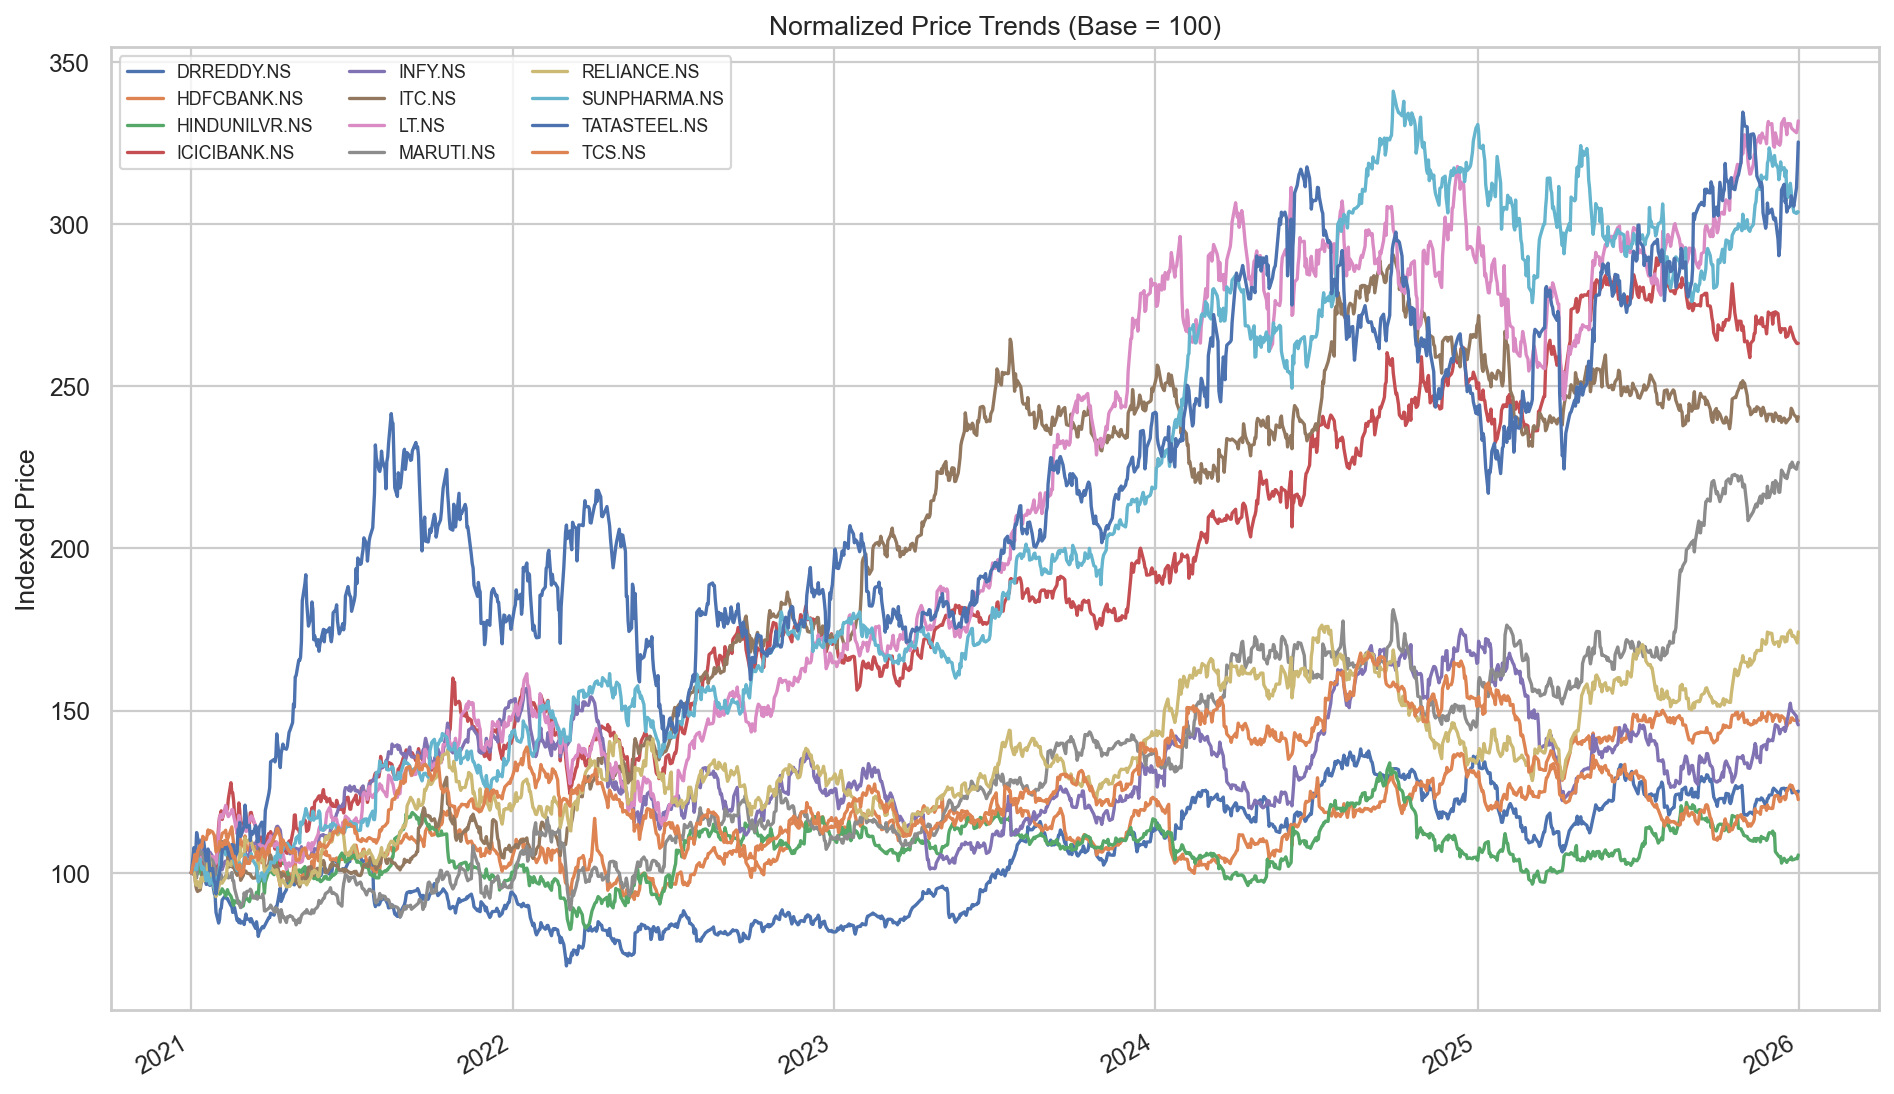

daily_log_returns.png


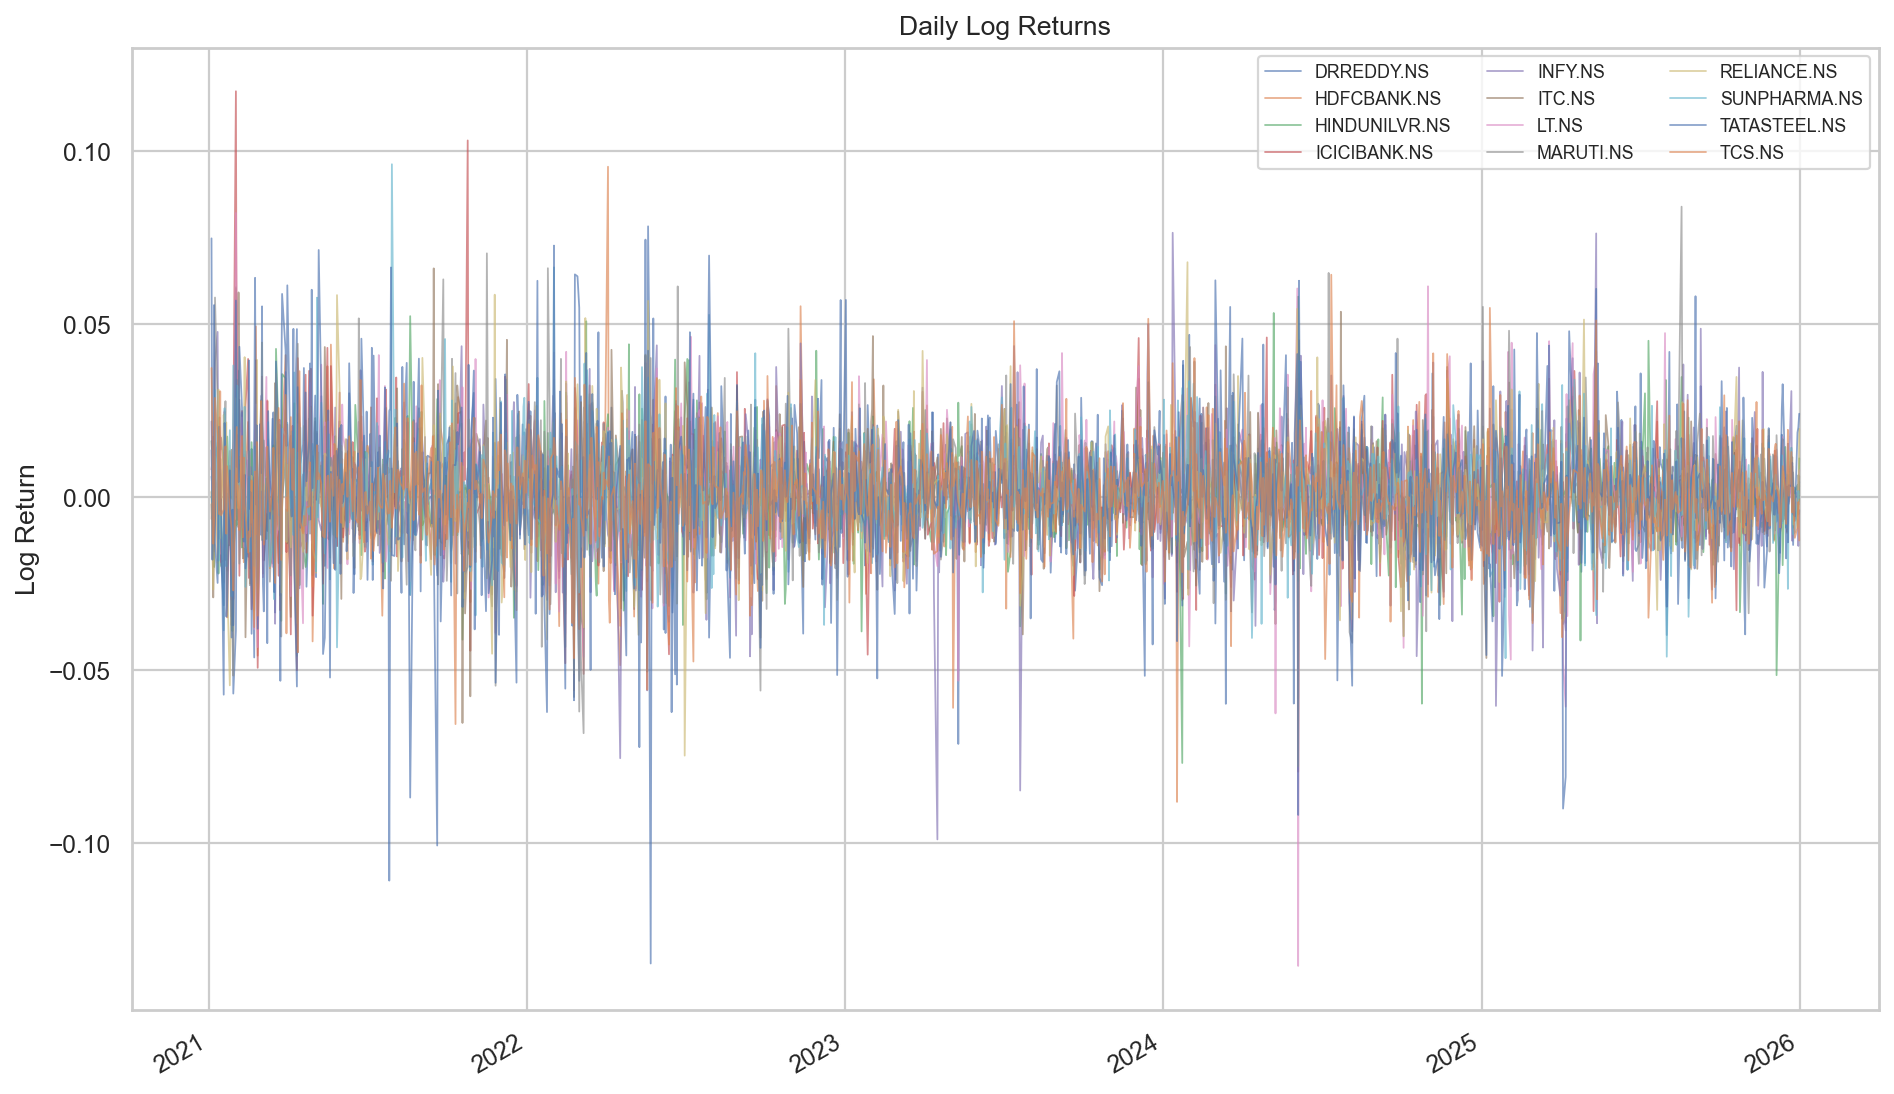

return_correlation_heatmap.png


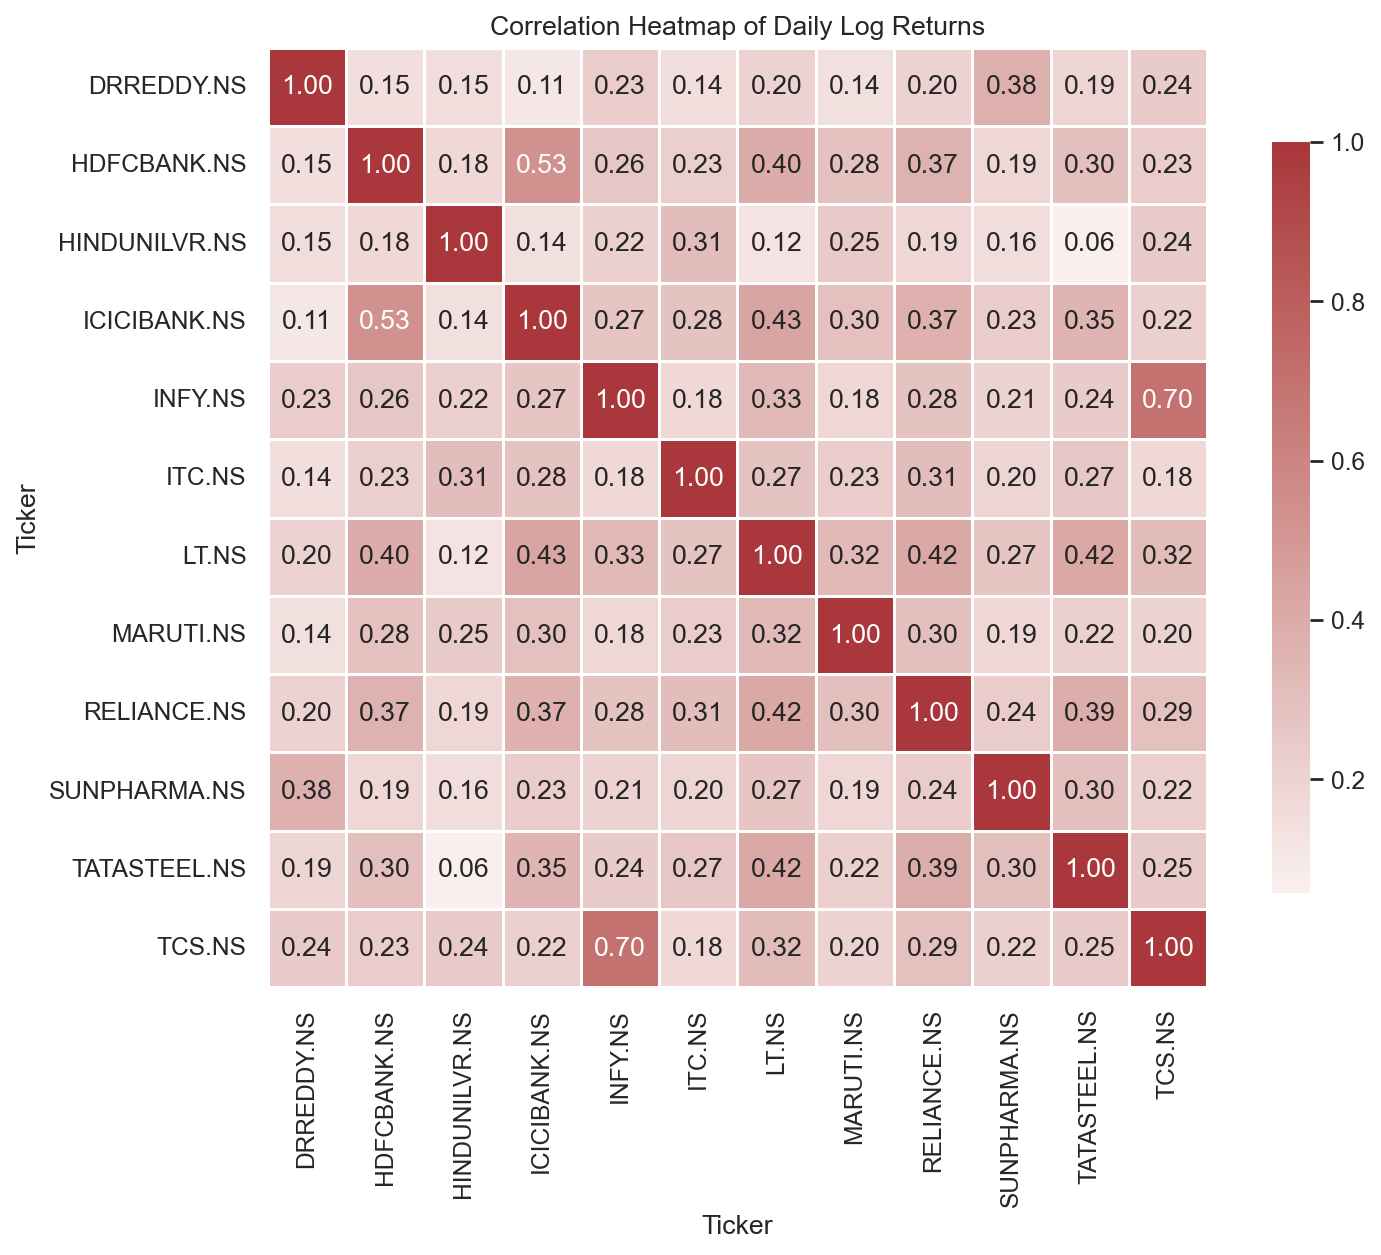

DRREDDY_NS_rolling_stats.png


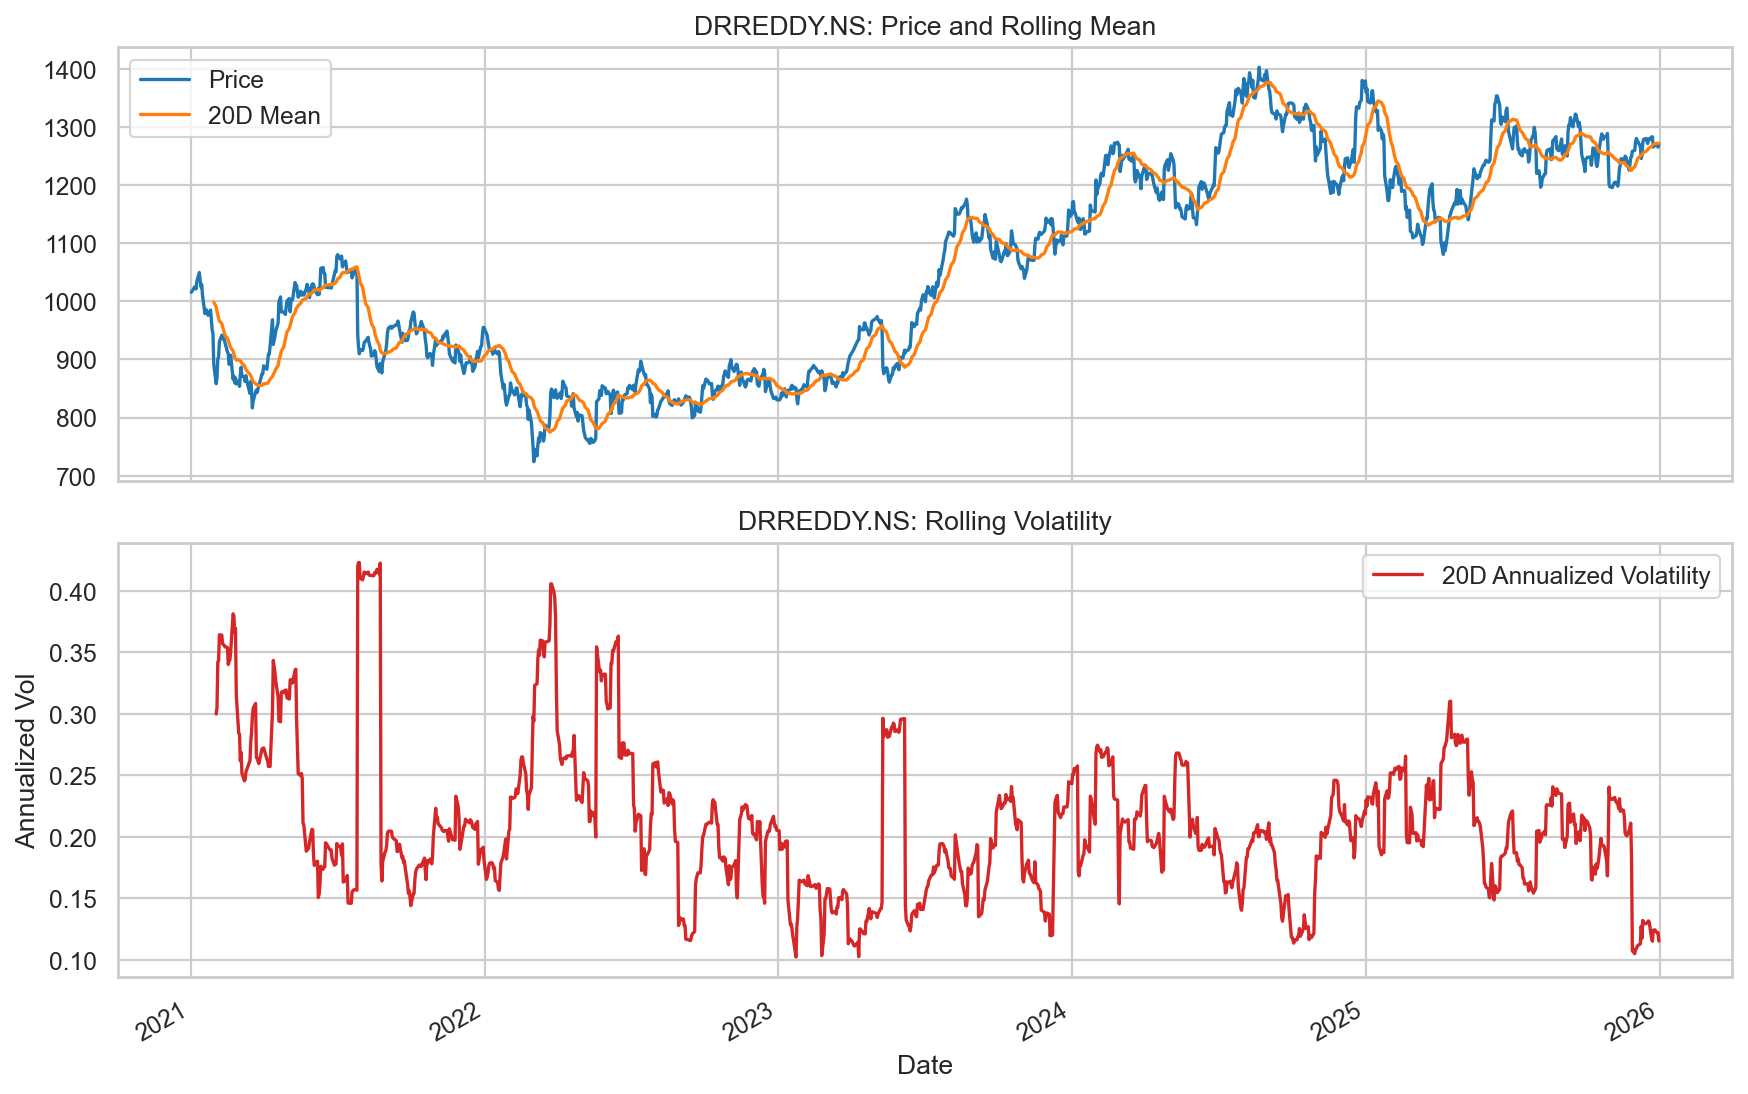

In [5]:
figure_paths = generate_core_figures(prices, returns)
for path in figure_paths[:4]:
    print(path.name)
    display(Image(filename=str(path)))

## 6. Forecasting Models

Models are trained on observations before 2025-07-01 and validated from 2025-07-01 to 2025-12-31. The implemented models are Naive, 20-day Moving Average, EWMA, and ARIMA when `statsmodels` is installed.

In [6]:
model_evaluation, validation_predictions, five_day_forecasts = run_forecasting_pipeline(prices)

display(model_evaluation.sort_values(["Ticker", "Selection Score"]).head(20))
display(five_day_forecasts.head(20))

,Ticker,Model,RMSE,MAPE,Directional Accuracy,Selection Score,Note
2,DRREDDY.NS,ExpSmoothing0.30,20.937868,1.298501,0.500000,0.811563,
0,DRREDDY.NS,Naive,14.376964,0.837665,0.000000,0.837665,
3,DRREDDY.NS,"ARIMA(0, 1, 2)",32.601172,2.043933,0.579365,1.155795,
1,DRREDDY.NS,MovingAverage20,30.893355,2.103135,0.547619,1.239347,
6,HDFCBANK.NS,ExpSmoothing0.30,8.882068,0.695336,0.531746,0.418029,
4,HDFCBANK.NS,Naive,6.973759,0.546372,0.000000,0.546372,
5,HDFCBANK.NS,MovingAverage20,15.144393,1.181749,0.523810,0.717490,
7,HDFCBANK.NS,"ARIMA(1, 1, 2)",17.124183,1.487302,0.523810,0.903005,
10,HINDUNILVR.NS,ExpSmoothing0.30,41.730711,1.260578,0.500000,0.787861,
8,HINDUNILVR.NS,Naive,28.946758,0.818515,0.000000,0.818515,


,Forecast Date,Ticker,Best Model,Horizon,Last Price,Forecast Price,Forecast Return
0,2026-01-01,DRREDDY.NS,ExpSmoothing0.30,1,1271.400024,1270.606688,-0.000624
1,2026-01-02,DRREDDY.NS,ExpSmoothing0.30,2,1271.400024,1270.606688,-0.000624
2,2026-01-05,DRREDDY.NS,ExpSmoothing0.30,3,1271.400024,1270.606688,-0.000624
3,2026-01-06,DRREDDY.NS,ExpSmoothing0.30,4,1271.400024,1270.606688,-0.000624
4,2026-01-07,DRREDDY.NS,ExpSmoothing0.30,5,1271.400024,1270.606688,-0.000624
5,2026-01-01,HDFCBANK.NS,ExpSmoothing0.30,1,991.200012,991.619927,0.000424
6,2026-01-02,HDFCBANK.NS,ExpSmoothing0.30,2,991.200012,991.619927,0.000424
7,2026-01-05,HDFCBANK.NS,ExpSmoothing0.30,3,991.200012,991.619927,0.000424
8,2026-01-06,HDFCBANK.NS,ExpSmoothing0.30,4,991.200012,991.619927,0.000424
9,2026-01-07,HDFCBANK.NS,ExpSmoothing0.30,5,991.200012,991.619927,0.000424


## 7. Model Evaluation and Predicted vs Actual Validation Plots

The best model is selected using validation error, with directional accuracy included in the selection score. Validation plots compare predicted and actual prices.

,Ticker,Best Model,Best Validation MAPE,Best Validation RMSE,Best Directional Accuracy,ARIMA Order,Last Price,Forecast Day 5 Price,Forecast Return 5D
0,DRREDDY.NS,ExpSmoothing0.30,1.298501,20.937868,0.500000,NaN,1271.400024,1270.606688,-0.000624
1,HDFCBANK.NS,ExpSmoothing0.30,0.695336,8.882068,0.531746,NaN,991.200012,991.619927,0.000424
2,HINDUNILVR.NS,ExpSmoothing0.30,1.260578,41.730711,0.500000,NaN,2315.899902,2297.280162,-0.008040
3,ICICIBANK.NS,ExpSmoothing0.30,0.869500,15.469886,0.452381,NaN,1342.900024,1348.123768,0.003890
4,INFY.NS,ExpSmoothing0.30,1.492897,27.332779,0.500000,NaN,1615.400024,1634.030303,0.011533
5,ITC.NS,ExpSmoothing0.30,0.761236,3.878654,0.492063,NaN,394.727448,394.591935,-0.000343
6,LT.NS,ExpSmoothing0.30,0.983425,46.302225,0.539683,NaN,4083.500000,4060.452579,-0.005644
7,MARUTI.NS,ExpSmoothing0.30,1.251441,273.029581,0.539683,NaN,16697.000000,16618.621177,-0.004694
8,RELIANCE.NS,ExpSmoothing0.30,1.105491,20.727785,0.500000,NaN,1570.400024,1556.924805,-0.008581
9,SUNPHARMA.NS,ExpSmoothing0.30,1.046073,22.909775,0.531746,NaN,1708.601196,1717.100836,0.004975


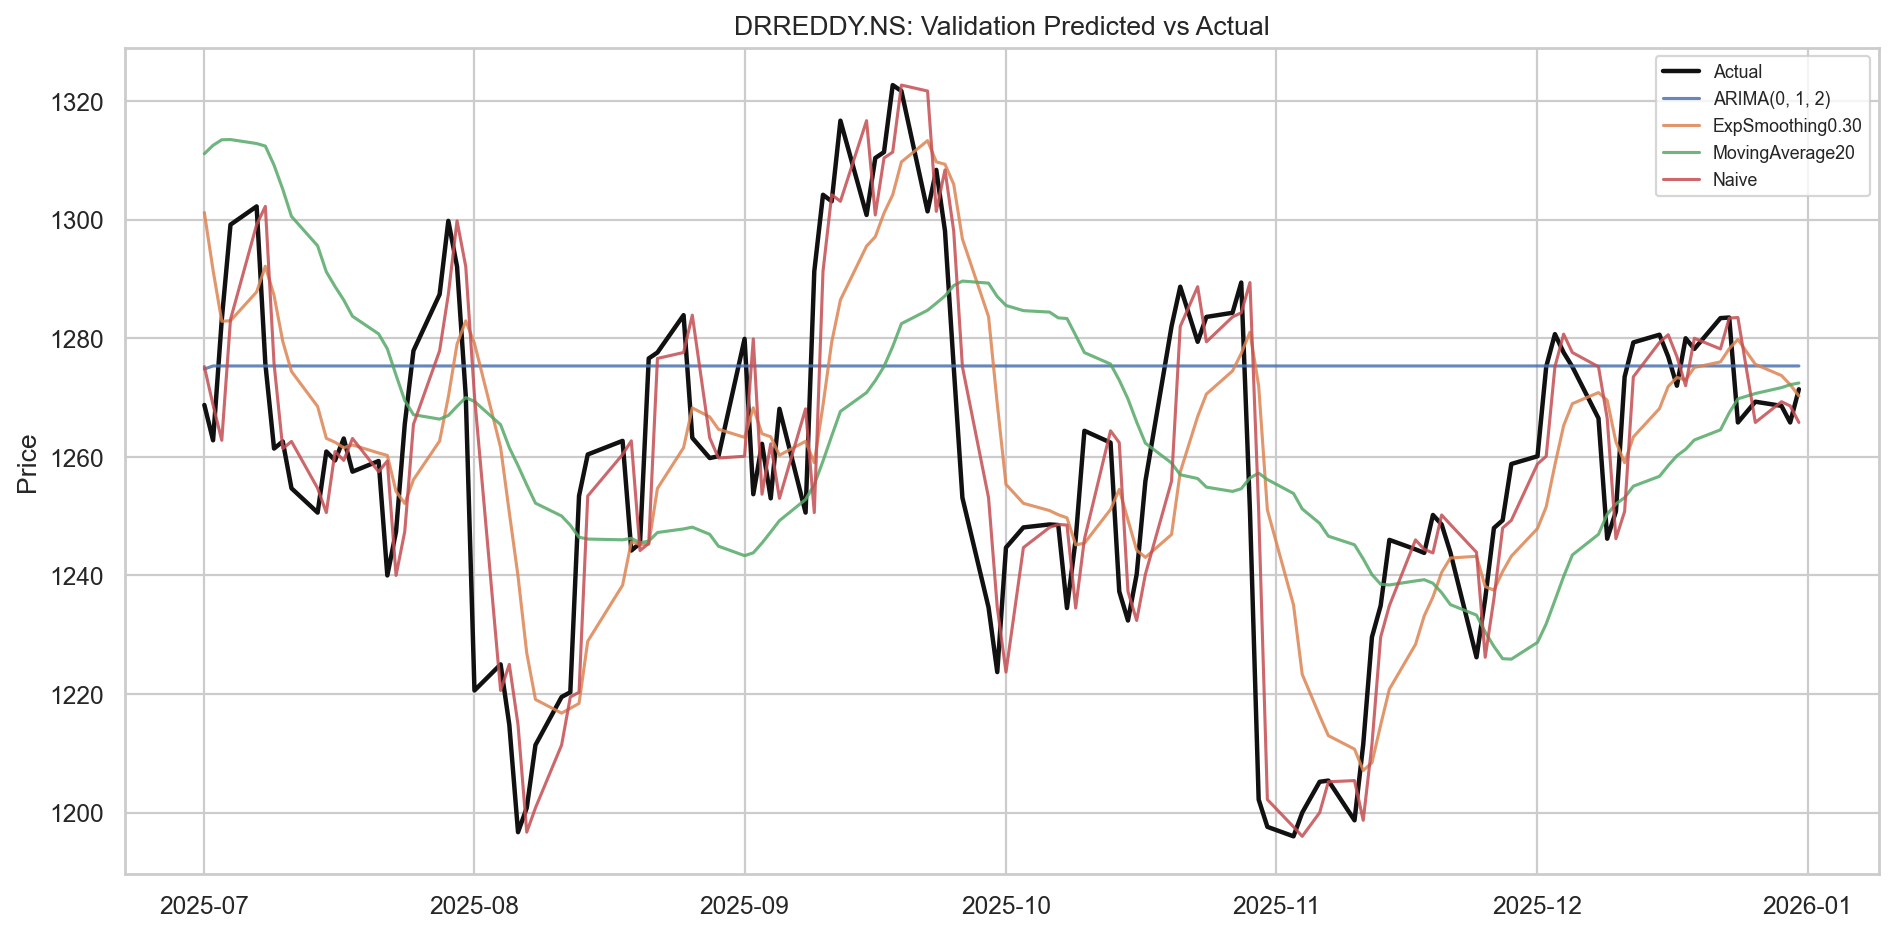

In [7]:
best_model_summary = pd.read_csv(FORECASTS_DIR / "best_model_summary.csv")
display(best_model_summary)

if not validation_predictions.empty:
    ticker = validation_predictions["Ticker"].iloc[0]
    forecast_plot = plot_validation_forecasts(validation_predictions, ticker)
    if forecast_plot:
        display(Image(filename=str(forecast_plot)))

## 8. Portfolio Construction

The project builds three strategies: forecast-guided, volatility-aware, and correlation-diversified. All use long-only weights, max 25% per stock, and min 5% per selected stock.

In [8]:
portfolio_inputs = prepare_portfolio_inputs(best_model_summary, selection_metrics)
portfolios, strategy_summary, final_portfolio = build_allocation_strategies(
    portfolio_inputs,
    returns,
)

display(strategy_summary)
display(final_portfolio[[
    "Ticker", "Company", "Sector", "Weight", "Target Rupee Allocation",
    "Last Price", "Estimated Quantity", "Forecast Return 5D",
    "Annualized Volatility", "Rationale"
]])

,Strategy,Holdings,Expected 5D Return,Annualized Portfolio Volatility,Risk Adjusted Expected Return,Average Abs Correlation,Cash After Rounding
0,A: Forecast-Guided,10,0.004680,0.148572,0.031502,0.274085,24222.827347
1,B: Volatility-Aware,10,0.002537,0.137888,0.018400,0.274085,24027.988754
2,C: Correlation-Diversified,10,0.004689,0.148419,0.031591,0.274085,23737.221512


,Ticker,Company,Sector,Weight,Target Rupee Allocation,Last Price,Estimated Quantity,Forecast Return 5D,Annualized Volatility,Rationale
20,SUNPHARMA.NS,Sun Pharmaceutical,Pharma,0.11877,118769.661023,1708.601196,69,0.004975,0.208421,Pharma exposure; ExpSmoothing0.30 forecast 0.5...
21,TCS.NS,Tata Consultancy Services,IT,0.25000,250000.000000,3148.955322,79,0.013645,0.207395,IT exposure; ExpSmoothing0.30 forecast 1.36%; ...
22,INFY.NS,Infosys,IT,0.25000,250000.000000,1615.400024,154,0.011533,0.240995,IT exposure; ExpSmoothing0.30 forecast 1.15%; ...
23,ICICIBANK.NS,ICICI Bank,Banking,0.08123,81230.338977,1342.900024,60,0.003890,0.219555,Banking exposure; ExpSmoothing0.30 forecast 0....
24,HDFCBANK.NS,HDFC Bank,Banking,0.05000,50000.000000,991.200012,50,0.000424,0.212324,Banking exposure; ExpSmoothing0.30 forecast 0....
25,ITC.NS,ITC,FMCG,0.05000,50000.000000,394.727448,126,-0.000343,0.198924,FMCG exposure; ExpSmoothing0.30 forecast -0.03...
26,MARUTI.NS,Maruti Suzuki,Auto,0.05000,50000.000000,16697.000000,2,-0.004694,0.231703,Auto exposure; ExpSmoothing0.30 forecast -0.47...
27,LT.NS,Larsen & Toubro,Infrastructure,0.05000,50000.000000,4083.500000,12,-0.005644,0.241100,Infrastructure exposure; ExpSmoothing0.30 fore...
28,TATASTEEL.NS,Tata Steel,Metals,0.05000,50000.000000,180.080002,277,-0.031414,0.330710,Metals exposure; ExpSmoothing0.30 forecast -3....
29,RELIANCE.NS,Reliance Industries,Energy,0.05000,50000.000000,1570.400024,31,-0.008581,0.227063,Energy exposure; ExpSmoothing0.30 forecast -0....


## 9. StockGro Execution Summary Template

StockGro execution is manual. Register/login with mobile number and OTP, use virtual capital only, search each stock, place market or limit orders, and record entry price, quantity, execution date, and screenshot/reference. Observe two consecutive trading days and record Day 2 closing prices.

In [9]:
execution_template = make_stockgro_execution_template(final_portfolio)
actuals_template = make_actual_results_template(five_day_forecasts)

display(execution_template)
display(actuals_template)

,Ticker,Company,Sector,Recommended Weight,Target Rupee Allocation,Estimated Quantity,Order Type,Execution Date,Entry Price,Screenshot/Reference,Day 2 Close,Notes
20,SUNPHARMA.NS,Sun Pharmaceutical,Pharma,0.11877,118769.661023,69,Market or Limit,,NaN,,NaN,
21,TCS.NS,Tata Consultancy Services,IT,0.25000,250000.000000,79,Market or Limit,,NaN,,NaN,
22,INFY.NS,Infosys,IT,0.25000,250000.000000,154,Market or Limit,,NaN,,NaN,
23,ICICIBANK.NS,ICICI Bank,Banking,0.08123,81230.338977,60,Market or Limit,,NaN,,NaN,
24,HDFCBANK.NS,HDFC Bank,Banking,0.05000,50000.000000,50,Market or Limit,,NaN,,NaN,
25,ITC.NS,ITC,FMCG,0.05000,50000.000000,126,Market or Limit,,NaN,,NaN,
26,MARUTI.NS,Maruti Suzuki,Auto,0.05000,50000.000000,2,Market or Limit,,NaN,,NaN,
27,LT.NS,Larsen & Toubro,Infrastructure,0.05000,50000.000000,12,Market or Limit,,NaN,,NaN,
28,TATASTEEL.NS,Tata Steel,Metals,0.05000,50000.000000,277,Market or Limit,,NaN,,NaN,
29,RELIANCE.NS,Reliance Industries,Energy,0.05000,50000.000000,31,Market or Limit,,NaN,,NaN,


,Ticker,Execution Date,Entry Price,Quantity,Actual Day 2 Close,Notes
0,DRREDDY.NS,,NaN,NaN,NaN,
1,HDFCBANK.NS,,NaN,NaN,NaN,
2,HINDUNILVR.NS,,NaN,NaN,NaN,
3,ICICIBANK.NS,,NaN,NaN,NaN,
4,INFY.NS,,NaN,NaN,NaN,
5,ITC.NS,,NaN,NaN,NaN,
6,LT.NS,,NaN,NaN,NaN,
7,MARUTI.NS,,NaN,NaN,NaN,
8,RELIANCE.NS,,NaN,NaN,NaN,
9,SUNPHARMA.NS,,NaN,NaN,NaN,


## 10. Predicted vs Actual Outcome Section

After entering actual Day 2 closes in `outputs/tables/stockgro_actuals_template.csv`, run the next cell to generate the comparison table. It is intentionally safe to run before actuals are filled; missing actuals remain blank.

In [10]:
comparison = compute_predicted_actual_comparison(
    five_day_forecasts=FORECASTS_DIR / "all_5day_forecasts.csv",
    actuals_csv=TABLES_DIR / "stockgro_actuals_template.csv",
    output_path=TABLES_DIR / "predicted_vs_actual_comparison.csv",
)
display(comparison)

,Stock,Forecasted Price,Forecasted Return,Actual Day 2 Close,Actual Return,Forecast Direction,Actual Direction,Direction Correct?,Error %,Notes
0,DRREDDY.NS,1270.606688,-0.000624,NaN,NaN,Down,Down,NaN,NaN,NaN
1,HDFCBANK.NS,991.619927,0.000424,NaN,NaN,Up/Flat,Down,NaN,NaN,NaN
2,HINDUNILVR.NS,2297.280162,-0.008040,NaN,NaN,Down,Down,NaN,NaN,NaN
3,ICICIBANK.NS,1348.123768,0.003890,NaN,NaN,Up/Flat,Down,NaN,NaN,NaN
4,INFY.NS,1634.030303,0.011533,NaN,NaN,Up/Flat,Down,NaN,NaN,NaN
5,ITC.NS,394.591935,-0.000343,NaN,NaN,Down,Down,NaN,NaN,NaN
6,LT.NS,4060.452579,-0.005644,NaN,NaN,Down,Down,NaN,NaN,NaN
7,MARUTI.NS,16618.621177,-0.004694,NaN,NaN,Down,Down,NaN,NaN,NaN
8,RELIANCE.NS,1556.924805,-0.008581,NaN,NaN,Down,Down,NaN,NaN,NaN
9,SUNPHARMA.NS,1717.100836,0.004975,NaN,NaN,Up/Flat,Down,NaN,NaN,NaN


## 11. Assumptions and Date Clarification

The brief mentions StockGro execution between May 11 and May 15, 2025, while the dataset extends to December 31, 2025. This notebook follows the requested modeling split through December 2025. The StockGro execution and Day 2 outcome sections are provided as manual templates because the live event execution window cannot be reproduced automatically after the event.

## 12. Conclusion

This notebook produces the required data, model evaluation, 5-day forecasts, risk metrics, allocation strategies, final recommended virtual portfolio, execution template, predicted-vs-actual template, figures, and report-ready tables.